## Лабораторная работа №1: регрессия

В этой работе мы:
* Исследуем датасет **Wine Quality** (UCI) и подготовим честную схему экспериментов;
* Построим простой baseline (константное предсказание) и посчитаем метрики RMSE и MAE;
* Обучим и сравним `LinearRegression`, `RandomForestRegressor` и `GradientBoostingRegressor` в одинаковых условиях;
* Исследуем важность признаков (feature importance) и сопоставим её с результатами первичного анализа;
* Разберём ошибки лучшей модели.

**Критерий качества:** RMSE на скрытой тестовой выборке должен быть меньше 0.70.

In [1]:
import io
import zipfile
import urllib.request
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
warnings.simplefilter("ignore")
%matplotlib inline

sns.set(style="darkgrid")
RANDOM_STATE = 42

# Часть 1. Загружаем данные

Датасет [Wine Quality](https://archive.ics.uci.edu/dataset/186/wine+quality) состоит из двух файлов: красное (`red`, 1599 образцов) и белое (`white`, 4898 образцов) вино. Признаки одинаковые (11 физико-химических показателей), целевая переменная `quality` &mdash; оценка дегустаторов от 0 до 10 (в данных встречаются значения 3&ndash;9).

Мы объединим оба файла в одну таблицу и добавим бинарный признак `is_red`, чтобы модель могла различать тип вина. Так у нас больше данных, а разницу между типами вина модель при необходимости выучит сама.

In [2]:
URL = "https://archive.ics.uci.edu/static/public/186/wine+quality.zip"
ZIP_PATH = Path("wine_quality.zip")

if not ZIP_PATH.exists():
    urllib.request.urlretrieve(URL, ZIP_PATH)

with zipfile.ZipFile(ZIP_PATH) as z:
    red = pd.read_csv(z.open("winequality-red.csv"), sep=";")
    white = pd.read_csv(z.open("winequality-white.csv"), sep=";")

red["is_red"] = 1
white["is_red"] = 0
data_raw = pd.concat([red, white], ignore_index=True)
data_raw.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,is_red
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,1
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,1
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,1
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,1
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,1


In [3]:
print("Размер таблицы:", data_raw.shape)
print("Пропусков:", data_raw.isna().sum().sum())
data_raw.dtypes

Размер таблицы: (6497, 13)
Пропусков: 0


fixed acidity           float64
volatile acidity        float64
citric acid             float64
residual sugar          float64
chlorides               float64
free sulfur dioxide     float64
total sulfur dioxide    float64
density                 float64
pH                      float64
sulphates               float64
alcohol                 float64
quality                   int64
is_red                    int64
dtype: object

Пропусков нет, все признаки числовые. Прежде чем делить данные на выборки, проверим, нет ли в таблице полных дубликатов: если одна и та же строка попадёт и в обучающую, и в тестовую выборку, мы будем проверять модель на объектах, которые она уже видела.

In [4]:
n_dup = data_raw.duplicated().sum()
print("Полных дубликатов: %d из %d (%.1f%%)" % (n_dup, len(data_raw), 100 * n_dup / len(data_raw)))

data = data_raw.drop_duplicates().reset_index(drop=True)
print("Размер после удаления дубликатов:", data.shape)

Полных дубликатов: 1177 из 6497 (18.1%)
Размер после удаления дубликатов: (5320, 13)


**Вывод.** В объединённой таблице 1177 полных дубликатов (18.1%): строки, совпадающие по всем 11 физико-химическим показателям, типу вина и `quality`. Это могут быть разные бутылки с одинаковыми измерениями, но отличить их от повторной записи мы не можем. Если оставить дубликаты, при случайном разбиении копия объекта окажется и в train, и в test, а Random Forest (деревья растут до листьев по одному объекту) просто «вспомнит» ответ. Оценка качества станет завышенной. Поэтому дубликаты удаляем **до** разбиения, остаётся 5320 объектов. Насколько это важно, покажем количественно в Части 12.

# Часть 2. Разбиваем данные

In [5]:
from sklearn.model_selection import train_test_split, KFold

y = data["quality"]
X = data.drop(columns=["quality"])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)
print("Train:", X_train.shape, " Test:", X_test.shape)

split_check = pd.DataFrame({
    "train, %": y_train.value_counts(normalize=True).sort_index() * 100,
    "test, %": y_test.value_counts(normalize=True).sort_index() * 100,
    "train, шт.": y_train.value_counts().sort_index(),
    "test, шт.": y_test.value_counts().sort_index(),
})
split_check.round(2)

Train: (4256, 12)  Test: (1064, 12)


,"train, %","test, %","train, шт.","test, шт."
quality,,,,
3,0.56,0.56,24,6
4,3.88,3.85,165,41
5,32.94,32.89,1402,350
6,43.66,43.70,1858,465
7,16.09,16.07,685,171
8,2.77,2.82,118,30
9,0.09,0.09,4,1


**Выбранное разбиение.**
* **Размер:** 80% / 20%, то есть 4256 объектов в обучающей и 1064 в тестовой выборке. Данных немного, поэтому большая часть нужна для обучения и кросс-валидации. Но и 1000+ тестовых объектов достаточно, чтобы оценить RMSE с разумной точностью (доверительный интервал bootstrap ниже имеет ширину около ±0.04).
* **Способ:** случайное разбиение со стратификацией по `quality` и фиксированным `random_state=42`. Объекты независимы и временной структуры нет, поэтому случайное разбиение подходит. Стратификация нужна из-за редких классов (`quality` = 3, 8, 9 вместе составляют всего ~3.4% данных, а класс 9 &mdash; 5 объектов): без неё при неудачном разбиении редкие классы могли бы почти целиком оказаться в одной части. По таблице видно, что доли классов в train и test совпадают.
* **Проблемы многократной оценки на одном тесте.** Если смотреть на тест при выборе модели, признаков или гиперпараметров, то решение подгоняется под конкретные тестовые объекты: победитель выбирается отчасти за счёт шума, итоговая оценка становится оптимистичной, а сама выборка перестаёт быть «новыми данными». Чем больше вариантов сравнивается, тем сильнее эффект. Поэтому всё подбирается на кросс-валидации по train, а тест используется только для финальных чисел.

Все решения (выбор гиперпараметров, сравнение моделей) мы будем принимать только по кросс-валидации **на обучающей выборке**. Для всех моделей используем одну и ту же схему `KFold` с фиксированным `random_state`, чтобы они сравнивались на одних и тех же фолдах. Тестовая выборка используется для итоговых чисел (по одному разу для каждой модели) и уже после выбора модели &mdash; только для анализа (bootstrap, permutation importance, разбор ошибок); никакие решения по ней не принимаются.

In [6]:
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# Часть 3. Первичный анализ данных

Все дальнейшие графики и статистики строим **только по обучающей выборке**, чтобы информация о тесте не повлияла на наши решения.

In [7]:
train_df = X_train.assign(quality=y_train)
train_df.describe().T[["mean", "std", "min", "50%", "max"]].round(3)

,mean,std,min,50%,max
fixed acidity,7.225,1.332,4.200,7.000,15.900
volatile acidity,0.343,0.167,0.080,0.300,1.580
citric acid,0.319,0.147,0.000,0.310,1.660
residual sugar,5.002,4.450,0.600,2.700,65.800
chlorides,0.057,0.036,0.009,0.047,0.611
free sulfur dioxide,29.992,17.824,1.000,28.000,289.000
total sulfur dioxide,113.737,56.554,7.000,115.750,440.000
density,0.995,0.003,0.987,0.995,1.039
pH,3.224,0.160,2.720,3.210,4.010
sulphates,0.533,0.146,0.220,0.510,1.980


**Выводы.**
* Признаки измерены в совершенно разных масштабах: `total sulfur dioxide` в среднем 114 (std 57), `chlorides` &mdash; 0.057 (std 0.036), `density` &mdash; около 0.995 (std 0.003). Для интерпретации коэффициентов линейной модели масштабирование понадобится.
* Целевая переменная `quality`: среднее 5.80, std 0.88, значения от 3 до 9.
* Есть выбросы справа: `residual sugar` максимум 65.8 при медиане 2.7, `free sulfur dioxide` максимум 289 при медиане 28, `chlorides` максимум 0.611 при медиане 0.047. Это реальные образцы вина, а не явные ошибки измерения, поэтому мы их не удаляем. Для линейной модели они опасны (большой вклад в квадратичную ошибку), деревья к ним нечувствительны.

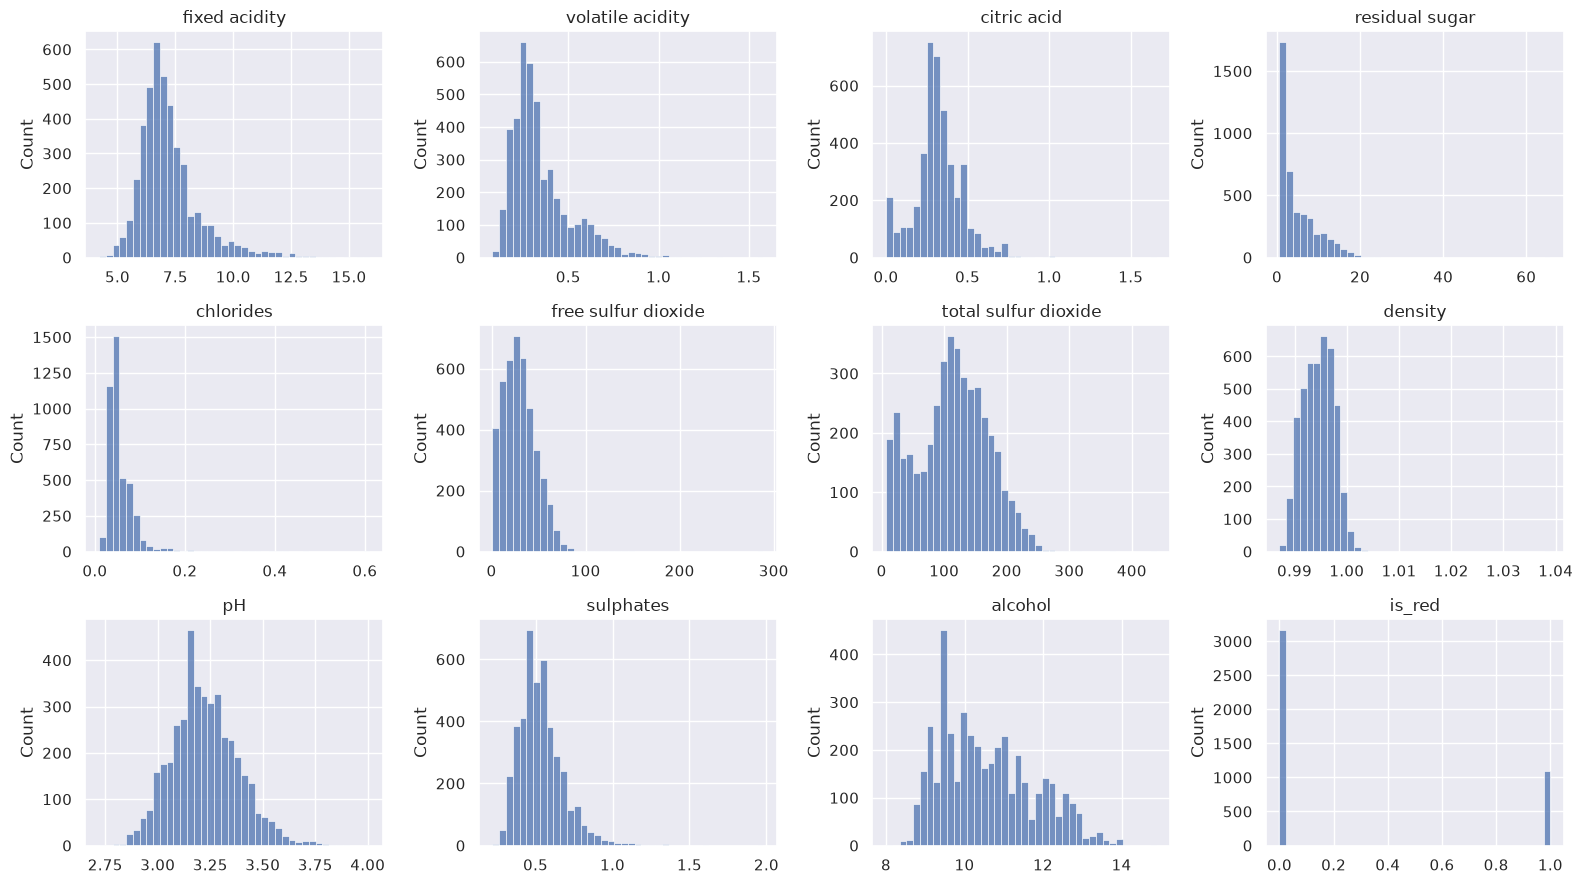

In [8]:
fig, axs = plt.subplots(figsize=(16, 9), nrows=3, ncols=4)
for ax, feature in zip(axs.ravel(), X_train.columns):
    sns.histplot(X_train[feature], bins=40, ax=ax)
    ax.set_title(feature)
    ax.set_xlabel("")
plt.tight_layout()

**Вывод.** Большинство признаков унимодальны и имеют правый хвост (сильнее всего `chlorides`, `residual sugar`, `sulphates`, `volatile acidity`), а `is_red` &mdash; бинарный признак, красных вин около 26%. Преобразования признаков (логарифм и т.п.) мы не делаем: деревьям они не нужны, а для линейной регрессии мы сознательно оставляем простой вариант, как на семинаре.

Средняя quality: белое = 5.853, красное = 5.628


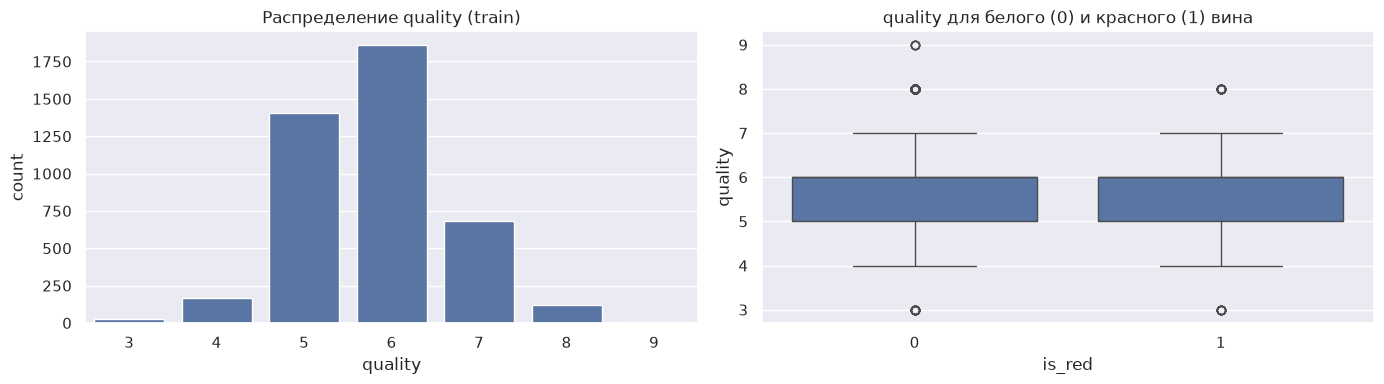

In [9]:
fig, axs = plt.subplots(figsize=(14, 4), ncols=2)
sns.countplot(x=y_train, ax=axs[0])
axs[0].set_title("Распределение quality (train)")
sns.boxplot(x="is_red", y="quality", data=train_df, ax=axs[1])
axs[1].set_title("quality для белого (0) и красного (1) вина")
plt.tight_layout()

print("Средняя quality: белое = %.3f, красное = %.3f" % (
    train_df.loc[train_df.is_red == 0, "quality"].mean(),
    train_df.loc[train_df.is_red == 1, "quality"].mean()))

**Выводы.**
* `quality` принимает всего 7 значений, и 76.6% объектов имеют оценку 5 или 6. Экстремальные оценки (3, 8, 9) встречаются редко (~3.4%), поэтому модель будет видеть их очень мало &mdash; к этому вернёмся в анализе ошибок.
* Белое вино оценено в среднем чуть выше красного (5.85 против 5.63), но разница 0.22 заметно меньше std таргета (0.88): тип вина сам по себе объясняет `quality` слабо (корреляция `is_red` с `quality` &mdash; около −0.11).

alcohol                 0.469
citric acid             0.094
pH                      0.051
free sulfur dioxide     0.049
sulphates               0.045
total sulfur dioxide   -0.061
residual sugar         -0.065
fixed acidity          -0.080
is_red                 -0.112
chlorides              -0.201
volatile acidity       -0.256
density                -0.328
dtype: float64

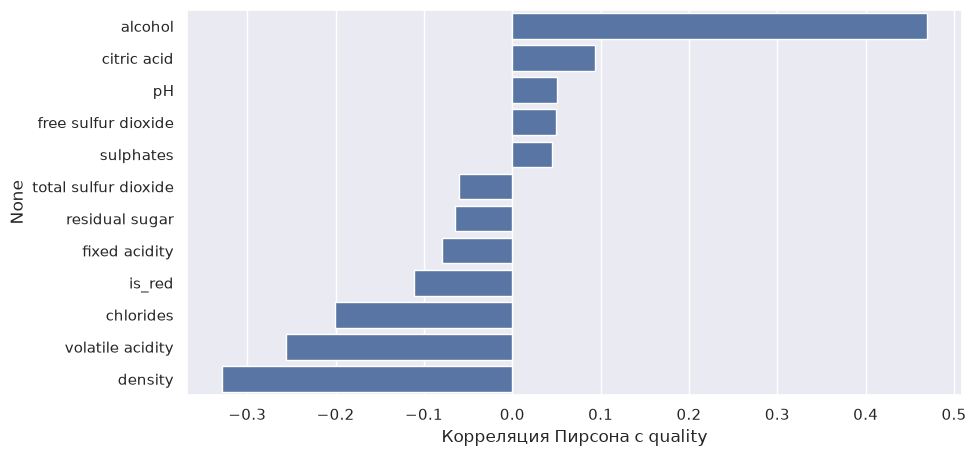

In [10]:
correlations = X_train.corrwith(y_train).sort_values(ascending=False)

plot = sns.barplot(y=correlations.index, x=correlations)
plot.figure.set_size_inches(10, 5)
plot.set_xlabel("Корреляция Пирсона с quality")
correlations.round(3)

**Выводы.**
* Корреляция `alcohol` и `quality` равна **0.47**: более крепкие вина в среднем получают более высокие оценки. Это самая сильная линейная связь в данных, и этот признак стоит ожидать среди главных в моделях. Но она умеренная: квадрат корреляции ≈ 0.22, то есть одним алкоголем линейно объясняется лишь около пятой части дисперсии `quality`.
* Далее идут `density` (−0.33), `volatile acidity` (−0.26, летучая кислотность: высокие значения дают уксусный привкус, и это логично снижает оценку) и `chlorides` (−0.20). У остальных признаков |r| < 0.12, то есть по отдельности линейно они с `quality` почти не связаны.
* Это корреляции, а не причинно-следственные связи. Кроме того, `density` сильно связана с `alcohol` (−0.66, см. ниже), поэтому её собственный вклад отделить сложно.

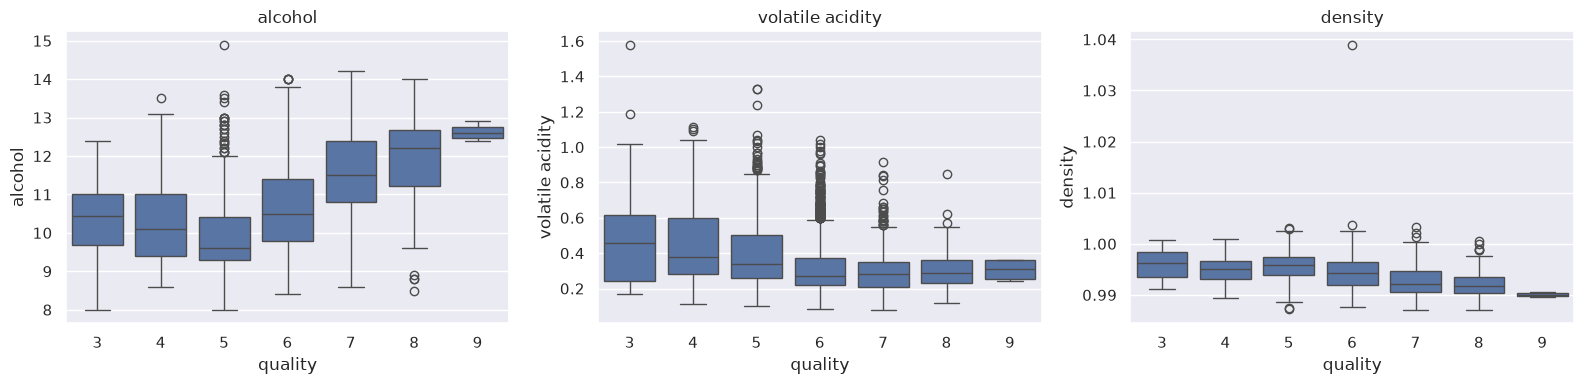

In [11]:
fig, axs = plt.subplots(figsize=(16, 4), ncols=3)
for ax, feature in zip(axs, ["alcohol", "volatile acidity", "density"]):
    sns.boxplot(x="quality", y=feature, data=train_df, ax=ax)
    ax.set_title(feature)
plt.tight_layout()

**Выводы.**
* Медианный `alcohol` растёт с качеством почти монотонно от класса 5 (≈ 9.6) до класса 9 (≈ 12.6). Но для классов 3 и 4 он выше, чем для 5 (≈ 10.4 и 10.1): на низком конце связь **немонотонна**, то есть линейная модель описывает её лишь отчасти.
* `volatile acidity` убывает с ростом `quality`, `density` в целом тоже (у `density` один сильный выброс ≈ 1.039).
* Распределения соседних классов сильно перекрываются. По одному признаку оценку не определить, нужна комбинация признаков, и ожидать очень точных предсказаний не стоит.

Text(0.5, 1.0, 'Корреляции между признаками (train)')

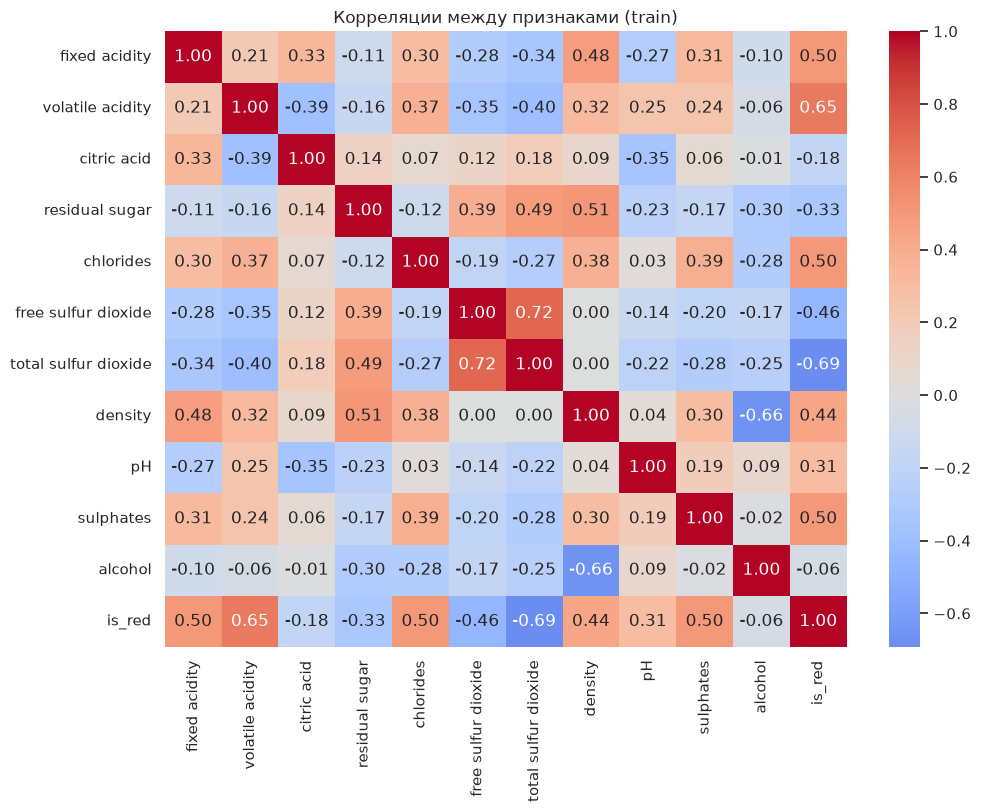

In [12]:
plt.figure(figsize=(11, 8))
sns.heatmap(X_train.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Корреляции между признаками (train)")

**Выводы.** Признаки сильно связаны между собой: `density` &ndash; `alcohol` (−0.66), `density` &ndash; `residual sugar` (0.51), `free` &ndash; `total sulfur dioxide` (0.72), `is_red` &ndash; `total sulfur dioxide` (−0.69), `is_red` &ndash; `volatile acidity` (0.65), `is_red` &ndash; `chlorides` (0.50). Следствия:
* в линейной регрессии возникает мультиколлинеарность: коэффициенты неустойчивы, а их знак может не совпадать со знаком корреляции (проверим через VIF);
* важность признаков в ансамблях «делится» между коррелированными признаками;
* тип вина во многом закодирован другими признаками (SO<sub>2</sub>, кислотность, хлориды), поэтому модель может «знать» тип вина и без `is_red`.

# Часть 4. Baseline

Baseline &mdash; одна константа для всех объектов. Для RMSE оптимальной константой является **среднее** значение таргета на обучающей выборке: именно оно минимизирует среднеквадратичную ошибку. (Для MAE оптимальна *медиана*, но основная метрика у нас RMSE, поэтому используем одну константу &mdash; среднее &mdash; для обеих метрик.)

In [13]:
from sklearn.metrics import root_mean_squared_error, mean_absolute_error

results = {}


def evaluate(name, y_true, y_pred):
    results[name] = {
        "RMSE": root_mean_squared_error(y_true, y_pred),
        "MAE": mean_absolute_error(y_true, y_pred),
    }
    print("%s: Test RMSE = %.4f, Test MAE = %.4f" % (name, results[name]["RMSE"], results[name]["MAE"]))


best_constant = y_train.mean()
print("Константа baseline (среднее на train) = %.4f" % best_constant)
pred_baseline = np.full(len(y_test), best_constant)
evaluate("Baseline", y_test, pred_baseline)

Константа baseline (среднее на train) = 5.7953
Baseline: Test RMSE = 0.8801, Test MAE = 0.6948


**Вывод.** Лучшая константа &mdash; среднее на train (5.795). Baseline даёт Test **RMSE = 0.8801** и **MAE = 0.6948**. RMSE константы-среднего примерно равен std таргета, и это точка отсчёта: модель с RMSE около 0.88 не извлекает из признаков ничего полезного. Порог лабораторной (0.70) требует снизить ошибку baseline примерно на 20%. (Для MAE оптимальна не среднее, а медиана, но baseline единый для обеих метрик.)

# Часть 5. Метрики

$$\text{MAE}(y, a) = \frac{1}{\ell}\sum_{i=1}^{\ell} |y_i - a(x_i)|, \qquad \text{RMSE}(y, a) = \sqrt{\frac{1}{\ell}\sum_{i=1}^{\ell} (y_i - a(x_i))^2}$$

Посмотрим на простом примере, почему для одной модели MAE и RMSE могут заметно различаться: два набора ошибок с одинаковой суммой модулей.

In [14]:
errors_even = np.array([1, 1, 1, 1])
errors_one_big = np.array([0, 0, 0, 4])

for name, e in [("равномерные ошибки", errors_even), ("одна большая ошибка", errors_one_big)]:
    print("%-20s MAE = %.2f, RMSE = %.2f" % (name, np.mean(np.abs(e)), np.sqrt(np.mean(e ** 2))))

равномерные ошибки   MAE = 1.00, RMSE = 1.00
одна большая ошибка  MAE = 1.00, RMSE = 2.00


**Ответы на вопросы.**
* **MAE** &mdash; средняя абсолютная ошибка: на сколько баллов `quality` модель ошибается в среднем. Измеряется в единицах таргета, штрафует ошибки линейно и устойчива к выбросам (оптимальное предсказание &mdash; условная медиана).
* **RMSE** &mdash; корень из средней квадратичной ошибки; тоже в единицах таргета, но интерпретируется как «типичная» ошибка с акцентом на крупные промахи (оптимальное предсказание &mdash; условное среднее). Это основная метрика лабораторной.
* **Почему RMSE сильнее реагирует на большие ошибки:** ошибка возводится в квадрат, поэтому ошибка 3 даёт вклад в 9 раз больше ошибки 1 (а не в 3 раза, как в MAE). В примере выше суммы модулей ошибок одинаковы, MAE = 1.00 в обоих случаях, а RMSE равен 1.00 и 2.00.
* **Почему для одной модели MAE и RMSE различаются:** всегда RMSE ≥ MAE, и разрыв тем больше, чем неравномернее ошибки (чем тяжелее хвост из крупных промахов). Если все ошибки одинаковы по модулю, метрики совпадают. Для нормально распределённых ошибок отношение RMSE/MAE ≈ 1.25.

# Часть 6. Линейная регрессия

Сначала обучим `LinearRegression` на «сырых» признаках, а затем в пайплайне с `StandardScaler`. Для обычной МНК-регрессии масштабирование не должно менять предсказания (оно меняет только масштаб коэффициентов), но оно необходимо, чтобы коэффициенты можно было сравнивать между собой.

In [15]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

lr_raw = LinearRegression().fit(X_train, y_train)

lr_pipeline = Pipeline([
    ("scaling", StandardScaler()),
    ("regression", LinearRegression()),
]).fit(X_train, y_train)

pred_lr_raw = lr_raw.predict(X_test)
pred_lr = lr_pipeline.predict(X_test)
print("Предсказания с масштабированием и без совпадают:", np.allclose(pred_lr_raw, pred_lr))

evaluate("Linear Regression", y_test, pred_lr)

cv_rmse = {}
cv_rmse["Linear Regression"] = -cross_val_score(
    lr_pipeline, X_train, y_train, cv=cv, scoring="neg_root_mean_squared_error"
)
print("CV RMSE (train, 5 фолдов) = %.4f +- %.4f" % (cv_rmse["Linear Regression"].mean(), cv_rmse["Linear Regression"].std()))

Предсказания с масштабированием и без совпадают: True
Linear Regression: Test RMSE = 0.7292, Test MAE = 0.5660
CV RMSE (train, 5 фолдов) = 0.7327 +- 0.0202


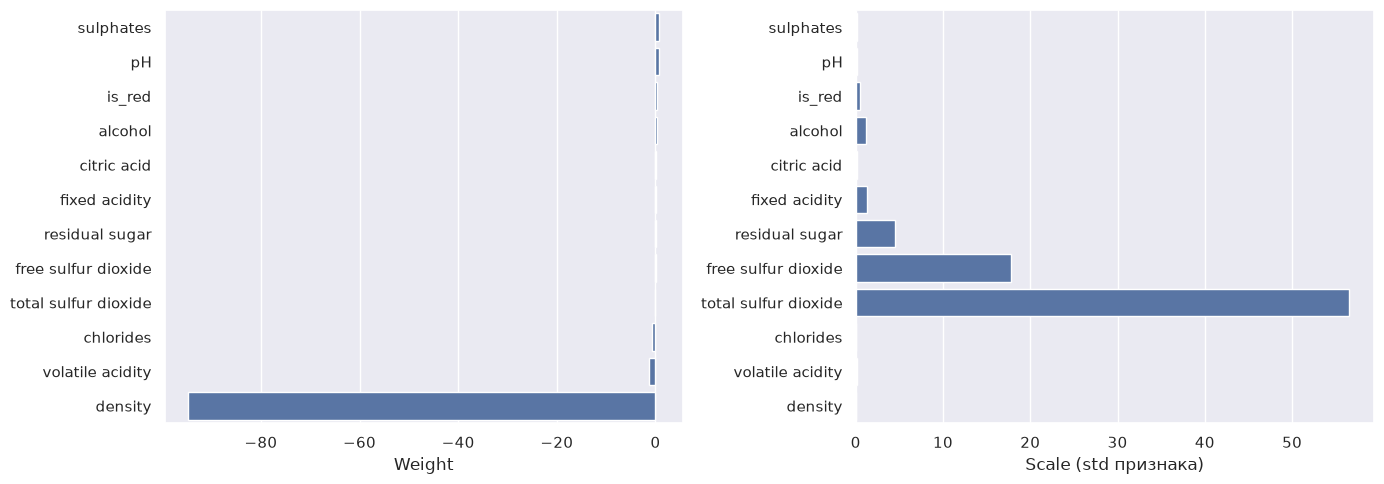

In [16]:
def show_weights(features, weights, scales):
    fig, axs = plt.subplots(figsize=(14, 5), ncols=2)
    sorted_weights = sorted(zip(weights, features, scales), reverse=True)
    weights = [x[0] for x in sorted_weights]
    features = [x[1] for x in sorted_weights]
    scales = [x[2] for x in sorted_weights]
    sns.barplot(y=features, x=weights, ax=axs[0])
    axs[0].set_xlabel("Weight")
    sns.barplot(y=features, x=scales, ax=axs[1])
    axs[1].set_xlabel("Scale (std признака)")
    plt.tight_layout()


show_weights(X_train.columns, lr_raw.coef_, X_train.std())

In [17]:
coef_table = pd.DataFrame({
    "coef (сырые признаки)": lr_raw.coef_,
    "std признака": X_train.std().values,
    "coef (стандартизованные)": lr_pipeline.named_steps["regression"].coef_,
}, index=X_train.columns)
coef_table["|coef| стандартизованный"] = coef_table["coef (стандартизованные)"].abs()
coef_table.sort_values("|coef| стандартизованный", ascending=False).round(4)

,coef (сырые признаки),std признака,coef (стандартизованные),|coef| стандартизованный
density,-94.7183,0.0030,-0.2810,0.2810
alcohol,0.2314,1.1907,0.2755,0.2755
residual sugar,0.0510,4.4500,0.2268,0.2268
volatile acidity,-1.3258,0.1666,-0.2209,0.2209
sulphates,0.8040,0.1461,0.1174,0.1174
is_red,0.2604,0.4368,0.1137,0.1137
free sulfur dioxide,0.0063,17.8237,0.1118,0.1118
pH,0.6656,0.1603,0.1067,0.1067
total sulfur dioxide,-0.0019,56.5538,-0.1054,0.1054
fixed acidity,0.0731,1.3315,0.0973,0.0973


In [18]:
def vif(df):
    out = {}
    for col in df.columns:
        others = df.drop(columns=col)
        r2 = LinearRegression().fit(others, df[col]).score(others, df[col])
        out[col] = 1 / (1 - r2)
    return pd.Series(out).sort_values(ascending=False)


vif(X_train).round(1)

density                 19.7
residual sugar           8.0
is_red                   7.1
alcohol                  5.1
fixed acidity            5.0
total sulfur dioxide     4.1
pH                       2.5
free sulfur dioxide      2.2
volatile acidity         2.2
citric acid              1.7
chlorides                1.6
sulphates                1.6
dtype: float64

**Результат.** Test RMSE = **0.7292**, MAE = 0.5660, CV RMSE = 0.7327 ± 0.0202. Модель заметно лучше baseline (0.88), но порог 0.70 **не проходит**. Ошибки на CV и на тесте согласуются, то есть переобучения нет: скорее, линейная зависимость слишком проста для этих данных (недообучение).

**Масштабирование.** Предсказания с `StandardScaler` и без него совпадают (`True`): для обычной МНК-регрессии без регуляризации масштаб признаков качество не меняет. Но на интерпретацию коэффициентов он влияет сильно. По сырым коэффициентам кажется, что `density` (−94.7) влияет в сотни раз сильнее, чем `alcohol` (0.23), но это лишь следствие масштаба (std у `density` 0.003, у `alcohol` 1.19). Чтобы коэффициенты можно было сравнивать, признаки нужно стандартизовать: тогда коэффициент показывает, на сколько изменится предсказание при росте признака на одно std. Масштабирование станет обязательным, если добавить регуляризацию (Ridge/Lasso) или оптимизировать градиентным спуском. Для деревьев оно не нужно.

**Какие признаки влияют сильнее.** По стандартизованным коэффициентам лидируют `density` (−0.28), `alcohol` (+0.28), `residual sugar` (+0.23) и `volatile acidity` (−0.22), затем идут `sulphates`, `is_red`, `free sulfur dioxide` (около 0.11&ndash;0.12). Почти нулевые коэффициенты у `chlorides` (−0.03) и `citric acid` (0.02), хотя у `chlorides` корреляция с `quality` была −0.20.

**Осторожно с интерпретацией.** VIF показывает сильную мультиколлинеарность: `density` &mdash; 19.7, `residual sugar` &mdash; 8.0, `is_red` &mdash; 7.1, `alcohol` &mdash; 5.1. Плотность почти полностью выражается через остальные признаки (прежде всего спирт и сахар), поэтому её коэффициент по сути «поправка» к ним. Знак `residual sugar` положительный (+0.23), хотя его корреляция с `quality` отрицательная (−0.07): так бывает, когда коррелированные признаки (`density`, `alcohol`, `residual sugar`) входят в модель вместе. Читать коэффициенты `density`, `alcohol` и `residual sugar` по отдельности нельзя. Надёжнее всех интерпретируются `alcohol` (+) и `volatile acidity` (−): они совпадают с первичным анализом и слабо коллинеарны (VIF 5.1 и 2.2).

# Часть 7. Random Forest

Гиперпараметры подбираем по сетке с кросс-валидацией на обучающей выборке (тот же объект `cv`, что и для остальных моделей).

In [19]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GridSearchCV

rf_grid = {
    "max_depth": [None, 20],
    "min_samples_leaf": [1, 2, 3, 5],
    "max_features": [0.33, 0.5, 1.0],
}
rf_search = GridSearchCV(
    RandomForestRegressor(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1),
    rf_grid, scoring="neg_root_mean_squared_error", cv=cv, n_jobs=1,
)
rf_search.fit(X_train, y_train)

print("Лучшие параметры:", rf_search.best_params_)
best_idx = rf_search.best_index_
cv_rmse["Random Forest"] = np.array([-rf_search.cv_results_["split%d_test_score" % i][best_idx] for i in range(5)])
print("CV RMSE (train, 5 фолдов) = %.4f +- %.4f" % (cv_rmse["Random Forest"].mean(), cv_rmse["Random Forest"].std()))

rf = rf_search.best_estimator_
pred_rf = rf.predict(X_test)
evaluate("Random Forest", y_test, pred_rf)

Лучшие параметры: {'max_depth': None, 'max_features': 0.33, 'min_samples_leaf': 1}
CV RMSE (train, 5 фолдов) = 0.6869 +- 0.0175
Random Forest: Test RMSE = 0.6798, Test MAE = 0.5256


In [20]:
rf_cv_table = pd.DataFrame(rf_search.cv_results_)[["param_max_depth", "param_min_samples_leaf", "param_max_features", "mean_test_score"]]
rf_cv_table["CV RMSE"] = -rf_cv_table.pop("mean_test_score")
rf_cv_table.sort_values("CV RMSE").head(8).round(4)

,param_max_depth,param_min_samples_leaf,param_max_features,CV RMSE
0,None,1,0.33,0.6869
1,None,2,0.33,0.6873
13,20,2,0.33,0.6875
12,20,1,0.33,0.6881
17,20,2,0.50,0.6894
5,None,2,0.50,0.6894
2,None,3,0.33,0.6894
14,20,3,0.33,0.6895


alcohol                 0.1803
density                 0.1081
volatile acidity        0.0991
free sulfur dioxide     0.0888
chlorides               0.0834
total sulfur dioxide    0.0823
sulphates               0.0776
residual sugar          0.0714
pH                      0.0710
citric acid             0.0694
fixed acidity           0.0641
is_red                  0.0046
dtype: float64

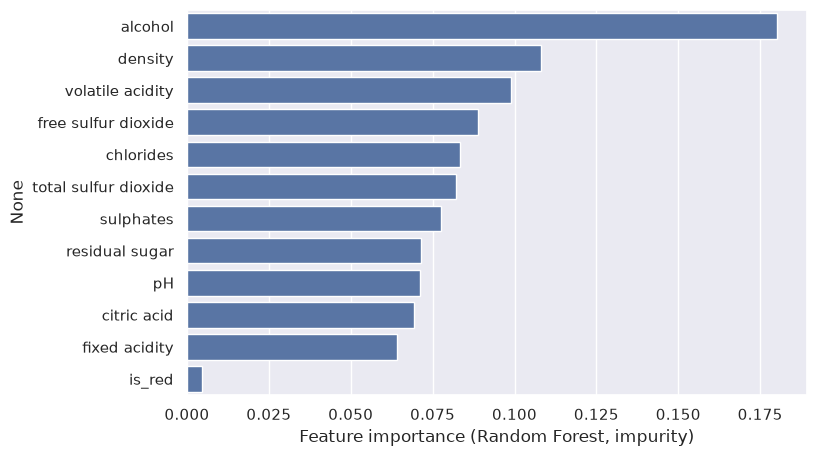

In [21]:
rf_importance = pd.Series(rf.feature_importances_, index=X_train.columns).sort_values(ascending=False)

plot = sns.barplot(y=rf_importance.index, x=rf_importance.values)
plot.figure.set_size_inches(8, 5)
plot.set_xlabel("Feature importance (Random Forest, impurity)")
rf_importance.round(4)

**Результат.** Test RMSE = **0.6798**, MAE = 0.5256, CV RMSE = 0.6869 ± 0.0175. Порог 0.70 пройден.

**Гиперпараметры.** Лучшие: полностью выросшие деревья (`max_depth=None`, `min_samples_leaf=1`) и `max_features=0.33`: на каждом разбиении рассматривается треть признаков, что делает деревья менее похожими друг на друга (важно при сильно коррелированных признаках). Лучшие конфигурации в таблице отличаются в 3&ndash;4-м знаке, то есть модель нечувствительна к гиперпараметрам.

**Feature importance.** Самые важные признаки: `alcohol` (0.18), `density` (0.11), `volatile acidity` (0.10), `free sulfur dioxide` (0.09), `chlorides` (0.08). Сравнение с предыдущими выводами:
* `alcohol` и `volatile acidity` подтверждают и первичный анализ, и линейную модель;
* `density` оказалась второй, как и в EDA/линейной модели, но здесь важно помнить, что она коррелирует с `alcohol` (−0.66), а impurity-важность вообще смещена в пользу непрерывных признаков с большим числом уникальных значений;
* `free sulfur dioxide` входит в топ-4, хотя линейная корреляция с `quality` почти нулевая (0.05): модель использует нелинейные или совместные эффекты, которые корреляция не видит;
* `is_red` &mdash; последний (0.005), хотя |corr| с `quality` около 0.11: информация о типе вина уже содержится в SO<sub>2</sub>, `volatile acidity`, `chlorides`.

# Часть 8. Gradient Boosting

In [22]:
from sklearn.ensemble import GradientBoostingRegressor

gb_grid = {
    "n_estimators": [200, 400],
    "learning_rate": [0.03, 0.05, 0.1],
    "max_depth": [3, 5],
    "subsample": [0.7, 1.0],
    "min_samples_leaf": [1, 5],
}
gb_search = GridSearchCV(
    GradientBoostingRegressor(random_state=RANDOM_STATE),
    gb_grid, scoring="neg_root_mean_squared_error", cv=cv, n_jobs=-1,
)
gb_search.fit(X_train, y_train)

print("Лучшие параметры:", gb_search.best_params_)
best_idx = gb_search.best_index_
cv_rmse["Gradient Boosting"] = np.array([-gb_search.cv_results_["split%d_test_score" % i][best_idx] for i in range(5)])
print("CV RMSE (train, 5 фолдов) = %.4f +- %.4f" % (cv_rmse["Gradient Boosting"].mean(), cv_rmse["Gradient Boosting"].std()))

gb = gb_search.best_estimator_
pred_gb = gb.predict(X_test)
evaluate("Gradient Boosting", y_test, pred_gb)

Лучшие параметры: {'learning_rate': 0.03, 'max_depth': 5, 'min_samples_leaf': 5, 'n_estimators': 400, 'subsample': 0.7}
CV RMSE (train, 5 фолдов) = 0.6921 +- 0.0111
Gradient Boosting: Test RMSE = 0.6839, Test MAE = 0.5259


alcohol                 0.2967
volatile acidity        0.1236
free sulfur dioxide     0.0992
sulphates               0.0793
total sulfur dioxide    0.0729
chlorides               0.0618
pH                      0.0608
residual sugar          0.0560
citric acid             0.0501
density                 0.0490
fixed acidity           0.0481
is_red                  0.0025
dtype: float64

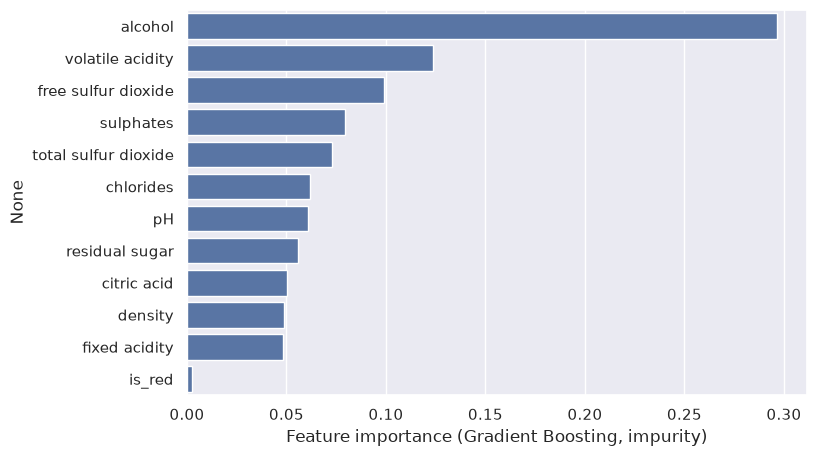

In [23]:
gb_importance = pd.Series(gb.feature_importances_, index=X_train.columns).sort_values(ascending=False)

plot = sns.barplot(y=gb_importance.index, x=gb_importance.values)
plot.figure.set_size_inches(8, 5)
plot.set_xlabel("Feature importance (Gradient Boosting, impurity)")
gb_importance.round(4)

**Результат.** Test RMSE = **0.6839**, MAE = 0.5259, CV RMSE = 0.6921 ± 0.0111. Порог 0.70 пройден. Выбранные параметры (`learning_rate=0.03`, 400 деревьев глубины 5, `subsample=0.7`, `min_samples_leaf=5`) &mdash; медленное обучение с заметной регуляризацией.

**Feature importance.** Лидеры: `alcohol` (0.30), `volatile acidity` (0.12), `free sulfur dioxide` (0.10), `sulphates` (0.08). По сравнению со случайным лесом:
* общее: `alcohol`, `volatile acidity` и `free sulfur dioxide` у обоих в тройке лидеров, `is_red` и `fixed acidity` в конце;
* главное отличие &mdash; `density`: у леса 2-е место (0.108), у бустинга лишь 10-е (0.049), а `alcohol` у бустинга доминирует сильнее (0.30 против 0.18). Вероятное объяснение: бустинг строит деревья последовательно, и после того как `alcohol` объяснил свою часть, `density` (коррелирует с ним на −0.66) почти ничего нового не добавляет. В лесу деревья независимы и видят случайные подмножества признаков, где `alcohol` бывает недоступен, и `density` его «подменяет». Permutation importance леса ставит `density` на 6-е место, то есть тоже ниже, чем impurity.
* Вывод: для коррелированных признаков ранжирование неустойчиво и зависит от алгоритма. Надёжный результат &mdash; устойчивая тройка `alcohol`, `volatile acidity`, `free sulfur dioxide`.

# Часть 9. Честное сравнение моделей

Все модели обучались на одной и той же обучающей выборке, гиперпараметры подбирались на одних и тех же фолдах `cv`, а метрики посчитаны на одной и той же тестовой выборке.

In [24]:
results_df = pd.DataFrame(results).T.loc[["Baseline", "Linear Regression", "Random Forest", "Gradient Boosting"]]
results_df.index.name = "Модель"
results_df.round(4)

,RMSE,MAE
Модель,,
Baseline,0.8801,0.6948
Linear Regression,0.7292,0.5660
Random Forest,0.6798,0.5256
Gradient Boosting,0.6839,0.5259


In [25]:
cv_table = pd.DataFrame({name: [v.mean(), v.std()] for name, v in cv_rmse.items()}, index=["CV RMSE mean", "CV RMSE std"]).T
cv_table.round(4)

,CV RMSE mean,CV RMSE std
Linear Regression,0.7327,0.0202
Random Forest,0.6869,0.0175
Gradient Boosting,0.6921,0.0111


In [26]:
# Выбор лучшей модели делаем по CV на train, а не по тесту
best_model_name = min(cv_rmse, key=lambda k: cv_rmse[k].mean())
print("Лучшая модель по CV на train:", best_model_name)

beat = [m for m in results_df.index if m != "Baseline" and results_df.loc[m, "RMSE"] < results_df.loc["Baseline", "RMSE"]]
print("Модели лучше baseline по RMSE:", ", ".join(beat))
print("Модели с RMSE < 0.70:", ", ".join(results_df.index[results_df["RMSE"] < 0.70]))

Лучшая модель по CV на train: Random Forest
Модели лучше baseline по RMSE: Linear Regression, Random Forest, Gradient Boosting
Модели с RMSE < 0.70: Random Forest, Gradient Boosting


In [27]:
# Насколько различия между моделями больше шума? Bootstrap по тестовым объектам.
preds = {"Linear Regression": pred_lr, "Random Forest": pred_rf, "Gradient Boosting": pred_gb}
rng = np.random.RandomState(RANDOM_STATE)
idx = rng.randint(0, len(y_test), size=(1000, len(y_test)))
y_arr = y_test.values


def boot_rmse(p):
    return np.sqrt(np.mean((y_arr[idx] - p[idx]) ** 2, axis=1))


boot = {name: boot_rmse(p) for name, p in preds.items()}
for name, b in boot.items():
    print("%-18s RMSE 95%% CI: [%.3f, %.3f]" % (name, *np.percentile(b, [2.5, 97.5])))

diff = boot["Gradient Boosting"] - boot["Random Forest"]
print("RMSE(GB) - RMSE(RF): среднее %.4f, 95%% CI [%.4f, %.4f]" % (diff.mean(), *np.percentile(diff, [2.5, 97.5])))

Linear Regression  RMSE 95% CI: [0.691, 0.768]
Random Forest      RMSE 95% CI: [0.641, 0.717]
Gradient Boosting  RMSE 95% CI: [0.646, 0.721]
RMSE(GB) - RMSE(RF): среднее 0.0040, 95% CI [-0.0062, 0.0137]


**Какие модели превзошли baseline.** Все три: Linear Regression (RMSE 0.729 против 0.880, снижение на 17%), Random Forest (0.680, на 23%) и Gradient Boosting (0.684, на 22%). Порог RMSE < 0.70 проходят Random Forest и Gradient Boosting, линейная регрессия его не проходит.

**Лучшая модель.** По CV на train лучшей выбрана Random Forest (0.6869), по тесту она тоже первая. Но Random Forest и Gradient Boosting на самом деле **неразличимы**: разность RMSE на bootstrap-выборках в среднем 0.004 с 95% интервалом [−0.006; 0.014], который включает 0, а CV-оценки 0.6869 ± 0.0175 и 0.6921 ± 0.0111 перекрываются. Утверждать, что один ансамбль лучше другого, нельзя.

**Почему деревья лучше линейной регрессии** (разница около 0.05 стабильно видна и в CV, и на тесте):
* **нелинейность и взаимодействия:** связь `alcohol` и `quality` немонотонна на низком конце, `free sulfur dioxide` важен для деревьев, хотя линейной связи нет; линейная модель такое выучить не может;
* **мультиколлинеарность:** коэффициенты линейной модели нестабильны (VIF до 19.7), а ансамбли деревьев к этому устойчивы;
* **выбросы и тяжёлые хвосты** признаков (`chlorides`, `residual sugar`, `free sulfur dioxide`) сильнее вредят линейной регрессии, чем деревьям.

**Почему RF ≈ GB и почему общий потолок невысок.** Данных немного (4.3 тыс.), а таргет &mdash; субъективная оценка дегустаторов с большим шумом. Лучшие модели объясняют лишь около 40% дисперсии (1 − 0.68²/0.88² ≈ 0.40), и оба ансамбля упираются в один и тот же шумовой потолок.

**MAE и RMSE.** У Random Forest RMSE/MAE = 0.680/0.526 ≈ 1.29, это чуть больше 1.25, ожидаемых для нормальных ошибок: небольшой вклад дают редкие крупные промахи (см. анализ ошибок).

# Часть 10. Feature importance

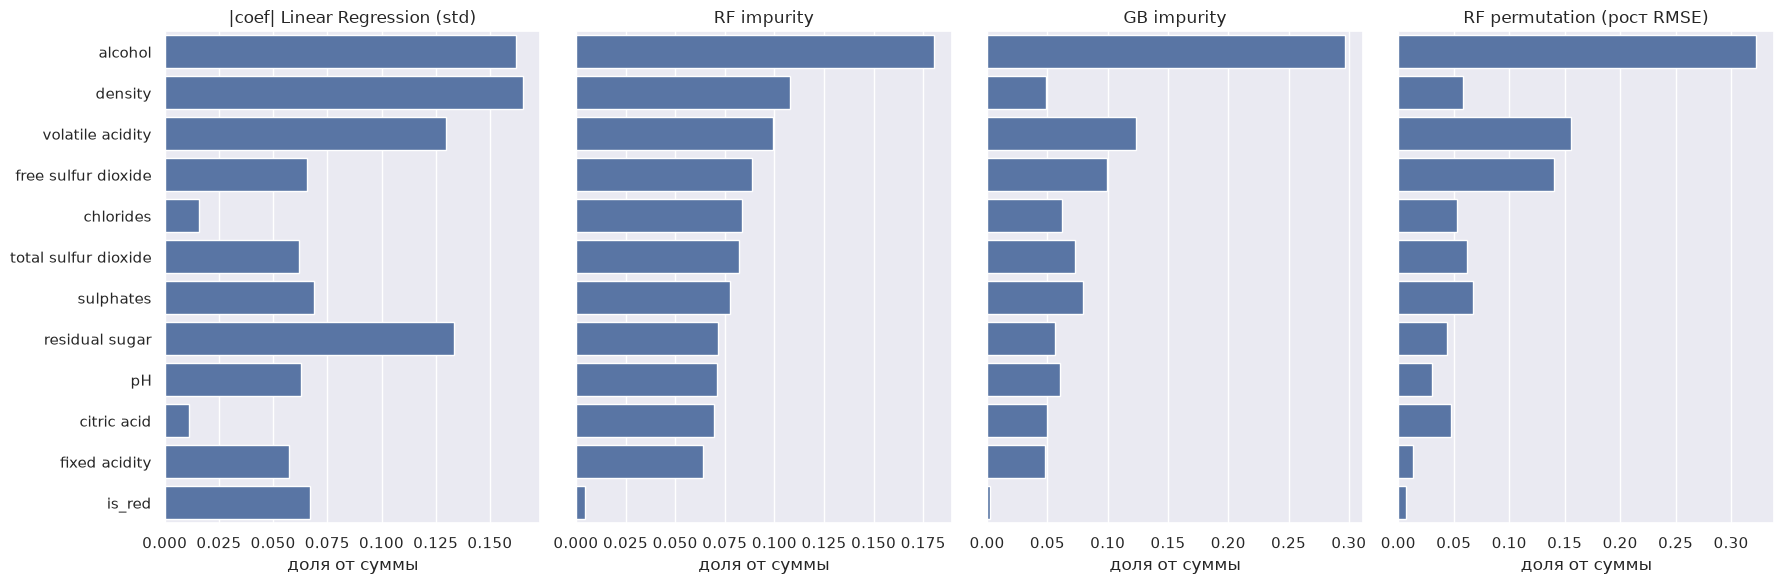

In [28]:
from sklearn.inspection import permutation_importance

perm = permutation_importance(
    rf, X_test, y_test, n_repeats=10, random_state=RANDOM_STATE,
    scoring="neg_root_mean_squared_error", n_jobs=-1,
)
rf_perm = pd.Series(perm.importances_mean, index=X_train.columns).sort_values(ascending=False)

importance = pd.DataFrame({
    "|corr| с quality (EDA)": correlations.abs(),
    "|coef| Linear Regression (std)": coef_table["|coef| стандартизованный"],
    "RF impurity": rf_importance,
    "GB impurity": gb_importance,
    "RF permutation (рост RMSE)": rf_perm,
})
# для сравнения приводим каждый столбец к доле от суммы
importance_share = importance / importance.sum()

fig, axs = plt.subplots(figsize=(18, 6), ncols=4, sharey=True)
order = importance_share["RF impurity"].sort_values(ascending=False).index
for ax, col in zip(axs, importance_share.columns[1:]):
    sns.barplot(y=order, x=importance_share.loc[order, col], ax=ax)
    ax.set_title(col)
    ax.set_xlabel("доля от суммы")
    ax.set_ylabel("")
plt.tight_layout()

In [29]:
rank_table = importance.rank(ascending=False).astype(int)
rank_table.sort_values("RF impurity")

,|corr| с quality (EDA),|coef| Linear Regression (std),RF impurity,GB impurity,RF permutation (рост RMSE)
alcohol,1,2,1,1,1
density,2,1,2,10,6
volatile acidity,3,4,3,2,2
free sulfur dioxide,11,7,4,3,3
chlorides,4,11,5,6,7
total sulfur dioxide,9,9,6,5,5
sulphates,12,5,7,4,4
residual sugar,8,3,8,8,9
pH,10,8,9,7,10
citric acid,6,12,10,9,8


In [30]:
print("Ранговая корреляция Спирмена между способами оценки важности:")
importance.corr(method="spearman").round(2)

Ранговая корреляция Спирмена между способами оценки важности:


,|corr| с quality (EDA),|coef| Linear Regression (std),RF impurity,GB impurity,RF permutation (рост RMSE)
|corr| с quality (EDA),1.00,0.33,0.42,-0.03,0.16
|coef| Linear Regression (std),0.33,1.00,0.55,0.24,0.40
RF impurity,0.42,0.55,1.00,0.71,0.87
GB impurity,-0.03,0.24,0.71,1.00,0.90
RF permutation (рост RMSE),0.16,0.40,0.87,0.90,1.00


**Ответ на вопрос: можно ли утверждать, что изменение признака *является причиной* изменения качества вина?** Нет. Feature importance показывает, насколько модель **использует** признак для предсказания, а не какой эффект даст вмешательство. Причины:
* *корреляция ≠ причинность:* `alcohol` может быть лишь маркером сорта винограда, региона, стиля или производителя, которые и влияют на оценку;
* *коррелированные признаки:* важность делится между ними или перетекает от одного к другому (`density`: 2-е место у RF и 10-е у GB, хотя она в основном отражает `alcohol` и `residual sugar`). Нельзя изменить спирт, не затронув плотность;
* *важность не показывает направление и форму эффекта* (в какую сторону и с каким порогом признак действует);
* *способ подсчёта влияет на результат:* impurity-важность смещена в пользу непрерывных признаков, permutation-важность при коррелированных признаках тоже искажена;
* данные *наблюдательные*, а не экспериментальные. Для причинных выводов нужен контролируемый эксперимент или каузальный анализ.

**Сопоставление с первичным анализом.**
* *Совпало:* `alcohol` &mdash; первый в EDA, RF, GB и RF permutation (и второй в линейной модели); `volatile acidity` в топ-4 везде.
* *Не совпало:* `chlorides` (4-й по EDA, 11-й в линейной модели, 5&ndash;7-й в деревьях); `is_red` (5-й по |corr|, но последний у деревьев, потому что тип вина закодирован другими признаками); `free sulfur dioxide` (11-й по |corr|, но 3&ndash;4-й у деревьев, то есть эффект нелинейный); `density` и `residual sugar` сильно зависят от модели.
* Ранжирования деревьев согласованы между собой (ранговая корреляция Спирмена: RF impurity и RF permutation 0.87, GB impurity и RF permutation 0.90), но слабо похожи на ранжирование по линейной корреляции из EDA (0.42 для RF и около 0 для GB): линейный анализ и нелинейные модели видят данные по-разному.

Permutation importance посчитана на тесте только для анализа: никаких решений о модели по ней не принималось.

# Часть 11. Анализ ошибок

In [31]:
models = {"Linear Regression": pred_lr, "Random Forest": pred_rf, "Gradient Boosting": pred_gb}
best_pred = models[best_model_name]
print("Анализируем модель:", best_model_name)

err = pd.DataFrame({"quality": y_test, "pred": best_pred})
err["error"] = err["quality"] - err["pred"]
err["abs_error"] = err["error"].abs()

print("Ошибка (y - pred): среднее = %.3f, std = %.3f" % (err["error"].mean(), err["error"].std()))
print("Квантили |ошибки|: медиана = %.3f, 90%% = %.3f, 99%% = %.3f, max = %.3f" % (
    err["abs_error"].median(), err["abs_error"].quantile(0.9), err["abs_error"].quantile(0.99), err["abs_error"].max()))
print("Доля объектов с |ошибкой| > 1: %.1f%%" % (100 * (err["abs_error"] > 1).mean()))

Анализируем модель: Random Forest
Ошибка (y - pred): среднее = 0.022, std = 0.680
Квантили |ошибки|: медиана = 0.437, 90% = 1.080, 99% = 2.185, max = 3.443
Доля объектов с |ошибкой| > 1: 11.9%


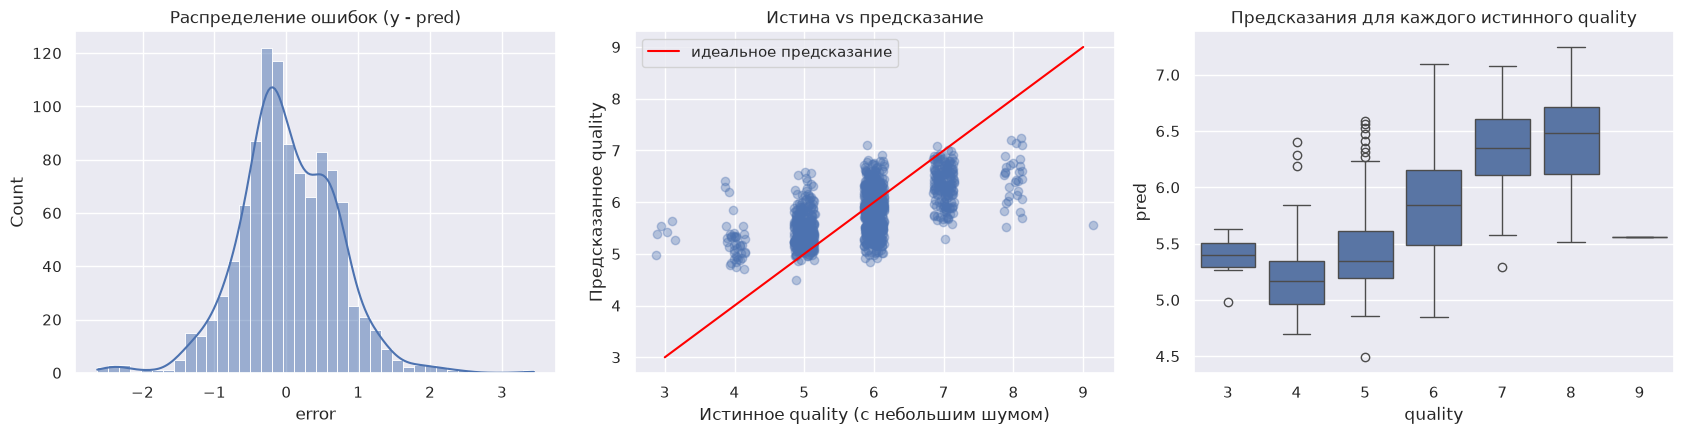

In [32]:
fig, axs = plt.subplots(figsize=(17, 4.5), ncols=3)

sns.histplot(err["error"], bins=40, kde=True, ax=axs[0])
axs[0].set_title("Распределение ошибок (y - pred)")

rng = np.random.RandomState(RANDOM_STATE)
axs[1].scatter(err["quality"] + rng.uniform(-0.15, 0.15, len(err)), err["pred"], alpha=0.35)
axs[1].plot([3, 9], [3, 9], color="red", label="идеальное предсказание")
axs[1].set_xlabel("Истинное quality (с небольшим шумом)")
axs[1].set_ylabel("Предсказанное quality")
axs[1].set_title("Истина vs предсказание")
axs[1].legend()

sns.boxplot(x="quality", y="pred", data=err, ax=axs[2])
axs[2].set_title("Предсказания для каждого истинного quality")
plt.tight_layout()

In [33]:
by_quality = err.groupby("quality").agg(
    n=("error", "size"),
    mean_pred=("pred", "mean"),
    bias=("error", "mean"),
    MAE=("abs_error", "mean"),
    RMSE=("error", lambda s: np.sqrt(np.mean(s ** 2))),
)
by_quality.round(3)

,n,mean_pred,bias,MAE,RMSE
quality,,,,,
3,6,5.368,-2.368,2.368,2.377
4,41,5.230,-1.230,1.230,1.288
5,350,5.426,-0.426,0.433,0.538
6,465,5.841,0.159,0.386,0.467
7,171,6.335,0.665,0.666,0.754
8,30,6.450,1.550,1.550,1.612
9,1,5.557,3.443,3.443,3.443


In [34]:
worst = err.sort_values("abs_error", ascending=False).head(10)
pd.concat([worst, X_test.loc[worst.index]], axis=1).round(3)

,quality,pred,error,abs_error,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,is_red
2012,9,5.557,3.443,3.443,9.1,0.270,0.45,10.60,0.035,28.0,124.0,0.997,3.20,0.46,10.4,0
1982,3,5.630,-2.630,2.630,6.9,0.390,0.40,4.60,0.022,5.0,19.0,0.992,3.31,0.37,12.6,0
1571,3,5.533,-2.533,2.533,8.5,0.260,0.21,16.20,0.074,41.0,197.0,0.998,3.02,0.50,9.8,0
2549,8,5.517,2.483,2.483,8.2,0.220,0.36,6.80,0.034,12.0,90.0,0.994,3.01,0.38,10.5,0
2783,3,5.417,-2.417,2.417,6.7,0.250,0.26,1.55,0.041,118.5,216.0,0.995,3.55,0.63,9.4,0
4984,4,6.407,-2.407,2.407,5.8,0.260,0.30,2.60,0.034,75.0,129.0,0.990,3.20,0.38,11.5,0
1165,3,5.383,-2.383,2.383,6.8,0.815,0.00,1.20,0.267,16.0,29.0,0.995,3.32,0.51,9.8,1
3881,8,5.700,2.300,2.300,7.0,0.530,0.43,6.10,0.029,6.0,76.0,0.991,3.08,0.50,12.5,0
4158,4,6.287,-2.287,2.287,6.7,0.640,0.30,1.20,0.030,18.0,76.0,0.989,3.16,0.60,12.9,0
1245,3,5.267,-2.267,2.267,7.3,0.980,0.05,2.10,0.061,20.0,49.0,0.997,3.31,0.55,9.7,1


In [35]:
# средние значения ключевых признаков по классам quality (train) для сравнения
key_features = ["alcohol", "volatile acidity", "density", "free sulfur dioxide", "total sulfur dioxide", "residual sugar"]
X_train.groupby(y_train)[key_features].mean().round(3)

,alcohol,volatile acidity,density,free sulfur dioxide,total sulfur dioxide,residual sugar
quality,,,,,,
3,10.252,0.521,0.996,40.333,125.708,5.165
4,10.228,0.448,0.995,21.142,105.070,4.133
5,9.888,0.393,0.996,29.579,119.034,5.443
6,10.670,0.314,0.994,30.857,114.110,5.107
7,11.531,0.294,0.993,29.801,104.242,4.106
8,11.916,0.308,0.992,32.500,109.725,4.575
9,12.625,0.305,0.990,34.750,114.000,2.500


**Распределение ошибок.** Анализируем лучшую по CV модель (Random Forest). Среднее ошибки 0.022 (систематического смещения в целом нет), std 0.68. Распределение примерно симметричное и колоколообразное, но с хвостами: медиана |ошибки| 0.44, 90-й процентиль 1.08, 99-й 2.19, максимум 3.44; у 11.9% объектов ошибка больше 1 балла.

**Истина vs предсказание.** Модель **сжимает предсказания к среднему**: для объектов с `quality` 3, 4 она предсказывает в среднем 5.4 и 5.2, для 8 и 9 &mdash; 6.5 и 5.6. Предсказания растут вместе с истинным значением (5.43 → 5.84 → 6.34 для классов 5, 6, 7), но с заметно меньшим наклоном, чем диагональ. Качество по классам:
* классы 5 и 6 (77% объектов) предсказываются лучше всего: RMSE 0.54 и 0.47;
* на краях ошибка резко растёт и смещена в сторону середины: класс 3 &mdash; смещение −2.37, класс 4 &mdash; −1.23, класс 8 &mdash; +1.55, класс 9 &mdash; +3.44 (один объект).

**Почему редкие значения `quality` предсказываются хуже.**
1. Мало примеров: в train всего 24 вина с оценкой 3 и 4 с оценкой 9, модели нечему учиться.
2. При минимизации квадратичной ошибки модель выгоднее предсказывать значение, близкое к условному среднему; если по признакам объект похож на «рядовое» вино, оценка будет около 5.5&ndash;6.
3. Признаки перекрываются: например, среднее `alcohol` у классов 3 и 4 (10.25 и 10.23) почти такое же, как у 5 и 6, поэтому «плохие» вина по признакам не отличаются от обычных.
4. Оценка дегустатора субъективна, и часть дисперсии `quality` не определяется измеренными признаками вообще.

**Объекты с самыми большими ошибками** (таблица выше; для сравнения даны средние признаков по классам):
* *Объект 2012* (`quality` = 9, предсказано 5.56): единственная девятка в тесте; `alcohol` = 10.4, типичный для класса 6 (10.67), а не для класса 9 (12.6). По измеренным признакам вино рядовое, а высокая оценка ими не объясняется.
* *Объекты 1982 и 4984* (3 → 5.63 и 4 → 6.41): `alcohol` 12.6 и 11.5, то есть по главному признаку они похожи на хорошие вина (у классов 7&ndash;8 среднее 11.5&ndash;11.9), но оценены низко. Здесь признаки не объясняют оценку. Обратный случай &mdash; объект 3881 (8 → 5.70): `alcohol` высокий (12.5), но модель предсказала 5.7, возможно из-за необычно низкого `free sulfur dioxide` (6).
* *Объекты 1165 и 1245* (оба красные, 3 → 5.38 и 5.27): очень высокая `volatile acidity` (0.815 и 0.98; в среднем у класса 3 около 0.52) и низкий `alcohol` (9.8 и 9.7), у первого ещё и аномальные `chlorides` = 0.267 (медиана 0.047). Модель верно определила направление (предсказала ниже среднего), но из-за сжатия к среднему не дотянула до 3.
* *Объекты 2783 и 1571* (оба 3): экстремальные значения SO<sub>2</sub> (`free` 118.5 и `total` 216 у первого, `total` 197 и `residual sugar` 16.2 у второго). Похожих вин в обучающей выборке очень мало, поэтому уверенного предсказания модель дать не может.

Итого: крупные ошибки сконцентрированы на редких крайних значениях и бывают двух типов: признаки не объясняют оценку (вино «выглядит» рядовым или наоборот) либо направление угадано верно, но масштаб занижен из-за сжатия к среднему. Улучшить это можно, добавив данных для краёв, подобрав другую функцию потерь или взвешивание объектов, но в рамках лабораторной мы этого не делаем.

# Часть 12. Дополнительно: что было бы с дубликатами

Повторим эксперимент по той же схеме, но **не удаляя** дубликаты, и посмотрим на ошибку отдельно для тестовых объектов, у которых есть точная копия в обучающей выборке, и для остальных. Параметры Random Forest возьмём уже найденные, повторный подбор здесь не нужен.

In [36]:
Xr = data_raw.drop(columns=["quality"])
yr = data_raw["quality"]
Xr_train, Xr_test, yr_train, yr_test = train_test_split(
    Xr, yr, test_size=0.2, random_state=RANDOM_STATE, stratify=yr
)

rf_dup = RandomForestRegressor(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1, **rf_search.best_params_)
rf_dup.fit(Xr_train, yr_train)
pred_dup = rf_dup.predict(Xr_test)

# для каждого тестового объекта: есть ли такая же строка в train
cols = list(Xr.columns)
train_keys = Xr_train.drop_duplicates().assign(in_train=1)
has_copy = Xr_test.reset_index(drop=True).merge(train_keys, how="left", on=cols)["in_train"].notna().values

print("Доля тестовых объектов с точной копией в train: %.1f%%" % (100 * has_copy.mean()))
print("RMSE на всём тесте (с дубликатами):      %.4f" % root_mean_squared_error(yr_test, pred_dup))
print("RMSE на объектах с копией в train:        %.4f" % root_mean_squared_error(yr_test[has_copy], pred_dup[has_copy]))
print("RMSE на объектах без копии в train:       %.4f" % root_mean_squared_error(yr_test[~has_copy], pred_dup[~has_copy]))

Доля тестовых объектов с точной копией в train: 27.5%
RMSE на всём тесте (с дубликатами):      0.5932
RMSE на объектах с копией в train:        0.2175
RMSE на объектах без копии в train:       0.6835


**Вывод.** Без дедупликации у 27.5% тестовых объектов есть точная копия в обучающей выборке. На них RMSE равен всего 0.2175 (модель просто «вспоминает» ответ), а на остальных объектах &mdash; 0.6835. Общий RMSE 0.5932 при этом выглядит как большой запас относительно порога 0.70, но он **завышен утечкой**. Наша честная оценка на дедуплицированных данных (0.6798) почти совпадает с качеством на действительно новых объектах (0.6835). Запас относительно порога 0.70 невелик, поэтому важно не обманывать себя красивой цифрой. Если скрытая тестовая выборка содержит копии обучающих объектов, реальное значение может оказаться ниже, но полагаться на это нельзя.

# Итог

Практическая линия работы: **Baseline → Linear Regression → Random Forest → Gradient Boosting → feature importance → анализ ошибок**.

| Модель | RMSE | MAE |
|---|---|---|
| Baseline | 0.8801 | 0.6948 |
| Linear Regression | 0.7292 | 0.5660 |
| Random Forest | 0.6798 | 0.5256 |
| Gradient Boosting | 0.6839 | 0.5259 |

**Главные выводы.**
* Все модели лучше baseline. Порог RMSE < 0.70 проходят Random Forest (0.680) и Gradient Boosting (0.684); линейная регрессия (0.729) не проходит. RF и GB статистически неразличимы, лучшей выбрана RF по CV на train.
* Корректность эксперимента: удалены дубликаты (иначе оценка завышена: 0.59 против 0.68 на новых объектах), разбиение стратифицированное с фиксированным `random_state`, все гиперпараметры подобраны кросс-валидацией на train, тест использован только для финальных чисел, все модели сравниваются на одной и той же выборке.
* Самый надёжный признак по всем методам &mdash; `alcohol`, далее `volatile acidity` и `free sulfur dioxide`; ранжирование коррелированных признаков (`density`, `residual sugar`) зависит от модели. Важность признаков не доказывает причинности.
* Модели хуже всего предсказывают редкие крайние оценки (3, 4, 8, 9): предсказания сжимаются к среднему, а часть оценки не объясняется измеренными признаками. Лучшие модели объясняют лишь около 40% дисперсии `quality`, и запас относительно порога 0.70 небольшой.